# BazaarLink: Delivery Performance and Customer Satisfaction EDA

**Capstone Day 4: Python EDA and statistics**

This notebook answers business questions Q1-Q11 from the BRD with descriptive statistics, charts and
hypothesis tests. It uses the reusable module in `src/` (`loader.py`, `analysis.py`) and exports the headline
KPIs to `kpi_summary.json`.

**KPI rules (BRD section 7, identical to SQL `03_analysis.sql`):**
* Revenue = sum of item price for delivered orders (freight excluded); AOV = Revenue / delivered orders
* Delivery KPIs use delivered orders with a delivered date only
* On time = delivered date on or before the estimated date; delay days = delivered minus estimated (positive = late)
* Negative review = score 1 or 2; customers counted by `customer_unique_id`
* Trends use complete months only: Jan 2017 to Aug 2018

| Section | Business question |
|---|---|
| 1 | Q1 Orders and revenue trend, seasonality |
| 2 | Q2 Revenue by category and state |
| 3 | Q4-Q6 On-time trend, delivery by state, where time is lost |
| 4 | Q7 Descriptive statistics: are estimated dates realistic? |
| 5 | Q8 Hypothesis tests: do late orders get lower reviews? |
| 6 | Q9 Conditional probability of a negative review |
| 7 | Q10 Correlation and regression: what explains delivery time? |
| 8 | Q11 Retention: do late first orders reduce repeat purchases? |
| 9 | Change request CR-01: instalments, AOV and cancellations |
| 10 | Findings and KPI export |

In [1]:
import os, sys, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sys.path.insert(0, os.path.join(os.getcwd(), "src"))
from loader import CleanDataLoader, MissingColumnError
from analysis import OrdersAnalyser, ALPHA

DATA_DIR = os.path.join("..", "02_data", "cleaned")
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

LATE, ON_TIME, NAVY, GREY = "#C0392B", "#1B998B", "#1F3A5F", "#8C96A3"
sns.set_theme(style="whitegrid", font_scale=0.95)
pd.set_option("display.max_columns", 30); pd.set_option("display.width", 160)

def save(fig, name):
    """Save a figure to figures/ for the deck and README."""
    fig.savefig(os.path.join(FIG_DIR, name), dpi=130, bbox_inches="tight")

print("Run at", datetime.now().strftime("%Y-%m-%d %H:%M"))

Run at 2026-11-07 23:07


In [2]:
loader = CleanDataLoader(DATA_DIR)
try:
    orders = loader.load_orders_master()
except MissingColumnError as err:
    print("Data problem:", err)
    raise
finally:
    print(pd.DataFrame(loader.load_log))

a = OrdersAnalyser(orders)
print(f"{len(orders):,} orders x {orders.shape[1]} columns")

                file   rows status  seconds            loaded_at
0  orders_master.csv  99441     ok     2.11  2026-11-07 23:07:45
99,441 orders x 49 columns


In [3]:
# Exception handling demo: a file without the required columns raises the custom MissingColumnError
try:
    loader.read_csv("customers.csv", required_columns=["customer_id", "column_that_does_not_exist"])
except MissingColumnError as err:
    print("Caught MissingColumnError ->", err)

Caught MissingColumnError -> customers.csv is missing required column(s): column_that_does_not_exist


In [4]:
kpis = a.kpis()
pd.Series(kpis, name="value").to_frame()

,value
orders,9.944100e+04
delivered_orders,9.647800e+04
revenue_brl,1.322150e+07
aov_brl,1.370400e+02
freight_brl,2.198276e+06
freight_ratio_pct,1.663000e+01
on_time_pct,9.323000e+01
avg_delivery_days,1.256000e+01
avg_delay_days,-1.188000e+01
avg_seller_handover_days,2.850000e+00


These headline KPIs match SQL query **SQL-18** and the Excel quick-look exactly (Revenue R$ 13,221,498.11,
on-time 93.23%, repeat customers 3.12%), which meets the "numbers match within 1%"
success criterion.

## 1. Q1: How have orders and revenue trended? Is there seasonality or a peak event?

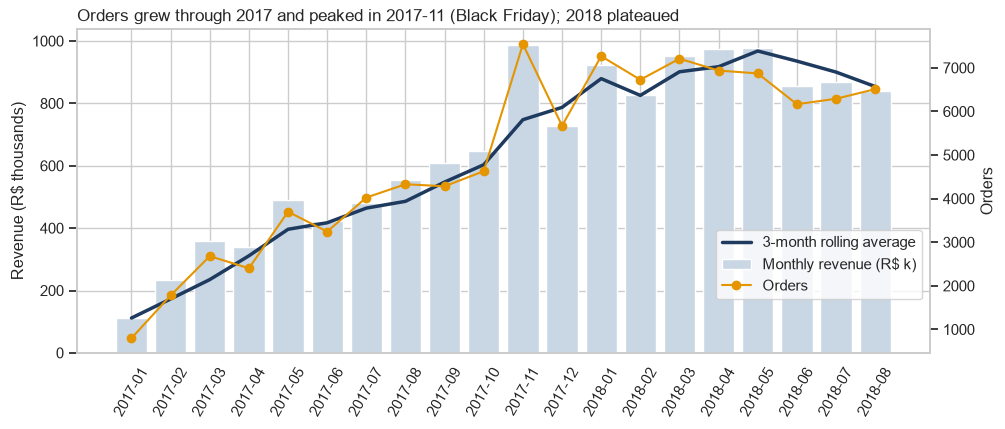

,orders,revenue,on_time_pct,avg_review,revenue_3m_avg
purchase_month,,,,,
2017-01,800,111798.36,97.07,4.06,111798.36
2017-02,1780,234223.40,97.04,4.02,173010.88
2017-03,2682,359198.85,95.44,4.07,235073.54
2017-04,2404,340669.68,93.44,4.05,311363.98
2017-05,3700,489338.25,97.01,4.14,396402.26
2017-06,3245,421923.37,96.97,4.15,417310.43
2017-07,4026,481604.52,97.21,4.17,464288.71
2017-08,4331,554699.70,97.09,4.24,486075.86
2017-09,4285,607399.67,95.61,4.19,547901.30


In [5]:
trend = a.monthly_trend()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(trend.index, trend["revenue"] / 1e3, color="#C9D6E3", label="Monthly revenue (R$ k)")
ax.plot(trend.index, trend["revenue_3m_avg"] / 1e3, color=NAVY, lw=2.5, label="3-month rolling average")
ax2 = ax.twinx(); ax2.plot(trend.index, trend["orders"], color="#E59500", marker="o", lw=1.5, label="Orders")
ax2.grid(False); ax.set_ylabel("Revenue (R$ thousands)"); ax2.set_ylabel("Orders")
ax.tick_params(axis="x", rotation=60)
peak = trend["orders"].idxmax()
ax.set_title(f"Orders grew through 2017 and peaked in {peak} (Black Friday); 2018 plateaued", loc="left", fontsize=12)
fig.legend(loc="lower right", bbox_to_anchor=(0.9, 0.22)); save(fig, "01_monthly_trend.png"); plt.show()
trend

In [6]:
top_days = (orders.groupby(orders["order_purchase_timestamp"].dt.date)["order_id"].count()
                  .sort_values(ascending=False).head(5).rename("orders"))
weekday = (orders.groupby(orders["order_purchase_timestamp"].dt.day_name())["order_id"].count()
                 .reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]))
display(top_days.to_frame()); display(weekday.to_frame("orders"))

,orders
order_purchase_timestamp,
2017-11-24,1176
2017-11-25,499
2017-11-27,403
2017-11-26,391
2017-11-28,380


,orders
order_purchase_timestamp,
Monday,16196
Tuesday,15963
Wednesday,15552
Thursday,14761
Friday,14122
Saturday,10887
Sunday,11960


**Finding:** orders rose steadily through 2017, peaked in **2017-11** (7,544 orders) and plateaued
at about 6,200-7,300 a month in 2018. The single biggest day is **24 Nov 2017 (Black Friday)**, more than double any
other day: a promotional event, not normal seasonality. Weekdays (Mon-Tue) are busier than weekends.

## 2. Q2: Which categories and customer states bring the most revenue?

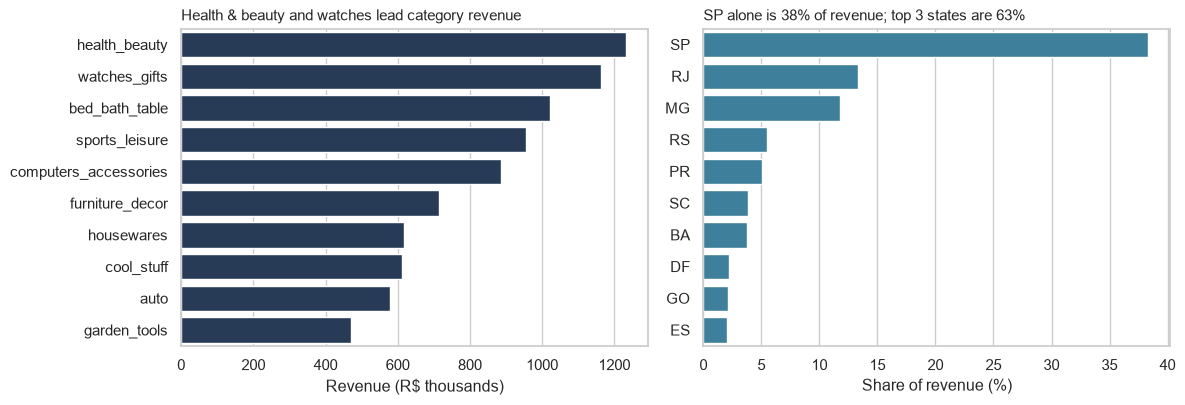

In [7]:
d = a.delivered()
cat = d.groupby("primary_category")["item_revenue"].sum().sort_values(ascending=False).head(10) / 1e3
state = d.groupby("customer_state")["item_revenue"].sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.barplot(x=cat.values, y=cat.index, color=NAVY, ax=axes[0])
axes[0].set_title("Health & beauty and watches lead category revenue", loc="left", fontsize=11)
axes[0].set_xlabel("Revenue (R$ thousands)"); axes[0].set_ylabel("")
share = (state / state.sum() * 100).head(10)
sns.barplot(x=share.values, y=share.index, color="#2E86AB", ax=axes[1])
axes[1].set_title(f"SP alone is {share.iloc[0]:.0f}% of revenue; top 3 states are {share.iloc[:3].sum():.0f}%", loc="left", fontsize=11)
axes[1].set_xlabel("Share of revenue (%)"); axes[1].set_ylabel("")
fig.tight_layout(); save(fig, "02_revenue_category_state.png"); plt.show()

## 3. Q4-Q6: Is on-time delivery improving? Where is it worst, and where is time lost?

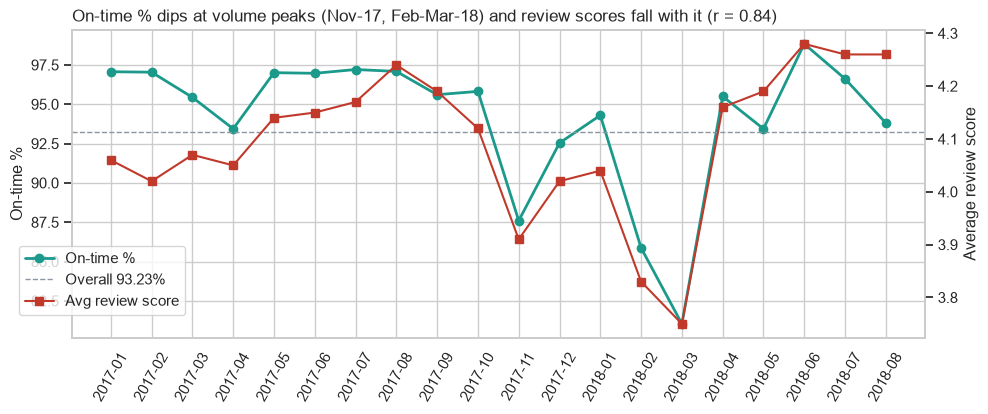

In [8]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(trend.index, trend["on_time_pct"], color=ON_TIME, marker="o", lw=2, label="On-time %")
ax.axhline(kpis["on_time_pct"], color=GREY, ls="--", lw=1, label=f"Overall {kpis['on_time_pct']}%")
ax2 = ax.twinx(); ax2.plot(trend.index, trend["avg_review"], color=LATE, marker="s", lw=1.5, label="Avg review score")
ax2.grid(False); ax.set_ylabel("On-time %"); ax2.set_ylabel("Average review score")
ax.tick_params(axis="x", rotation=60)
r = trend[["on_time_pct", "avg_review"]].corr().iloc[0, 1]
ax.set_title(f"On-time % dips at volume peaks (Nov-17, Feb-Mar-18) and review scores fall with it (r = {r:.2f})",
             loc="left", fontsize=12)
fig.legend(loc="lower left", bbox_to_anchor=(0.07, 0.15)); save(fig, "03_on_time_trend.png"); plt.show()

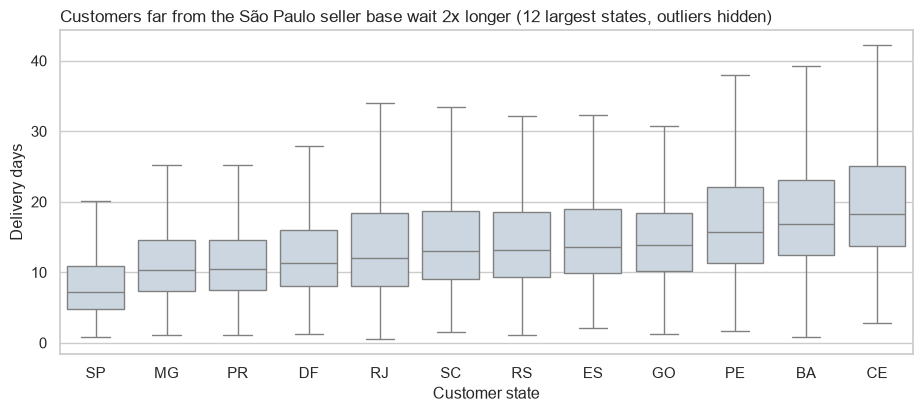

In [9]:
m = a.measurable()
top_states = m["customer_state"].value_counts().head(12).index
order_by = m[m["customer_state"].isin(top_states)].groupby("customer_state")["delivery_days"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 4.2))
sns.boxplot(data=m[m["customer_state"].isin(top_states)], x="customer_state", y="delivery_days",
            order=order_by, showfliers=False, color="#C9D6E3", ax=ax)
ax.set_title("Customers far from the São Paulo seller base wait 2x longer (12 largest states, outliers hidden)",
             loc="left", fontsize=12)
ax.set_xlabel("Customer state"); ax.set_ylabel("Delivery days")
save(fig, "04_delivery_days_by_state_box.png"); plt.show()

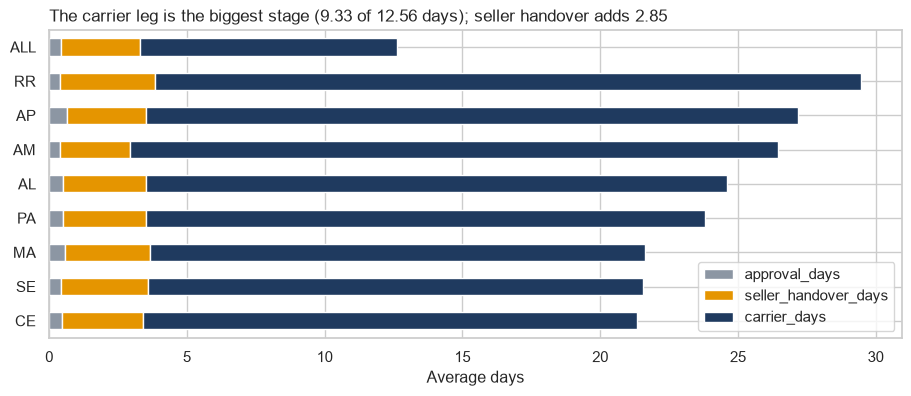

,approval_days,seller_handover_days,carrier_days,delivery_days,orders
customer_state,,,,,
RR,0.40,3.43,25.64,29.39,41
AP,0.64,2.88,23.66,27.19,67
AM,0.41,2.52,23.52,26.43,145
AL,0.49,3.02,21.09,24.54,397
PA,0.51,3.02,20.29,23.77,946
MA,0.58,3.08,17.97,21.57,717
SE,0.42,3.17,17.95,21.52,335
CE,0.47,2.92,17.93,21.27,1279


In [10]:
by_state = a.stage_summary(by="customer_state").sort_values("delivery_days", ascending=False)
overall = a.stage_summary()
plot = pd.concat([overall.to_frame("ALL").T, by_state.head(8)])[["approval_days", "seller_handover_days", "carrier_days"]]
fig, ax = plt.subplots(figsize=(11, 4))
plot.plot(kind="barh", stacked=True, color=[GREY, "#E59500", NAVY], ax=ax)
ax.invert_yaxis(); ax.set_xlabel("Average days")
ax.set_title(f"The carrier leg is the biggest stage ({overall['carrier_days']} of {overall['delivery_days']} days); "
             f"seller handover adds {overall['seller_handover_days']}", loc="left", fontsize=12)
save(fig, "05_stage_breakdown.png"); plt.show()
by_state.head(8)

**Finding (Q6):** on average an order spends **0.43 days** in payment approval,
**2.85 days** with the seller before handover and **9.33 days** with the carrier.
The carrier leg dominates, and it is longest for remote North/Northeast states (RR, AP, AM above 23 days).
Seller handover is smaller but is the stage BazaarLink can control directly through seller policy.
By region, the late rate is Northeast 12.7%, North 8.6%, Central-West 6.5%, Southeast 6.1%, South 5.9%.

## 4. Q7: Descriptive statistics. Are estimated delivery dates realistic?

In [11]:
desc_cols = ["delivery_days", "estimated_days", "delay_days", "approval_days", "seller_handover_days",
             "carrier_days", "review_score", "item_revenue", "freight_value"]
a.describe(desc_cols, m)

,count,mean,median,std,min,25%,50%,75%,max,skew
delivery_days,96470.0,12.56,10.22,9.55,0.53,6.77,10.22,15.72,209.63,3.83
estimated_days,96470.0,23.74,23.23,8.76,2.01,18.33,23.23,28.41,155.14,0.91
delay_days,96470.0,-11.88,-12.00,10.18,-147.00,-17.00,-12.00,-7.00,188.00,2.02
approval_days,96456.0,0.43,0.01,0.86,0.00,0.01,0.01,0.60,30.89,4.43
seller_handover_days,95130.0,2.85,1.85,3.49,0.00,0.90,1.85,3.62,125.76,5.15
carrier_days,96446.0,9.33,7.10,8.76,0.00,4.10,7.10,12.03,205.19,4.55
review_score,95824.0,4.16,5.00,1.28,1.00,4.00,5.00,5.00,5.00,-1.48
item_revenue,96470.0,137.04,86.50,209.05,0.85,45.90,86.50,149.90,13440.00,9.89
freight_value,96470.0,22.79,17.17,21.56,0.00,13.85,17.17,24.02,1794.96,12.28


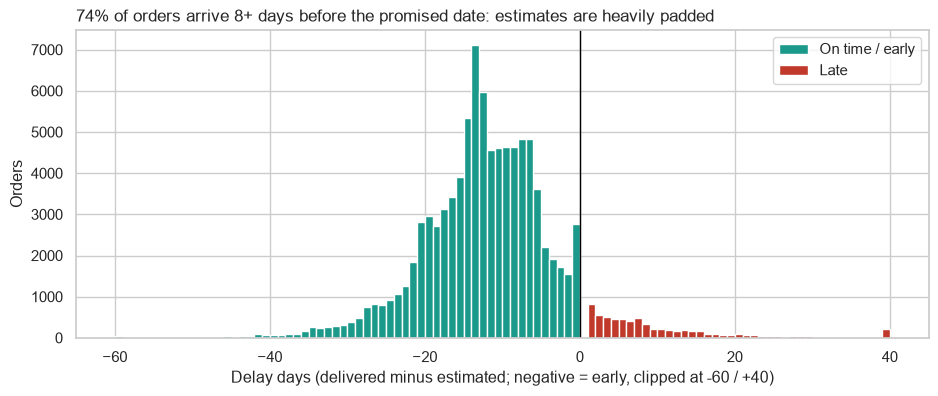

IQR fences for delivery days: -6.7 to 29.1; outliers above: 4,903 orders (kept, see DQ log)


In [12]:
fig, ax = plt.subplots(figsize=(11, 4))
clip = m["delay_days"].clip(-60, 40)
ax.hist(clip[clip <= 0], bins=range(-60, 1), color=ON_TIME, label="On time / early")
ax.hist(clip[clip > 0], bins=range(1, 41), color=LATE, label="Late")
ax.axvline(0, color="black", lw=1)
early8 = (m["delay_days"] <= -8).mean() * 100
ax.set_title(f"{early8:.0f}% of orders arrive 8+ days before the promised date: estimates are heavily padded",
             loc="left", fontsize=12)
ax.set_xlabel("Delay days (delivered minus estimated; negative = early, clipped at -60 / +40)"); ax.set_ylabel("Orders")
ax.legend(); save(fig, "06_delay_histogram.png"); plt.show()
lo, hi = a.iqr_bounds(m["delivery_days"])
print(f"IQR fences for delivery days: {lo:.1f} to {hi:.1f}; outliers above: {(m['delivery_days'] > hi).sum():,} orders (kept, see DQ log)")

**Finding (Q7):** shoppers are promised **23.7 days** on average but receive orders in
**12.6 days**. The median order arrives **12 days early** and
**74%** arrive 8 or more days early. The estimates are not realistic: they are padded so much that the on-time
rate looks good, while the long promise itself may discourage purchases. Delivery days are right-skewed
(skew 3.8): the mean is pulled up by a long tail of very slow deliveries, so medians are reported alongside means.

## 5. Q8: Do late orders get significantly lower review scores?

**Test 1: Mann-Whitney U (main test)**
* **H0:** review scores of late orders and on-time orders come from the same distribution.
* **H1:** late orders have **lower** review scores (one-sided).
* **alpha = 0.05**
* **Why this test:** review score is an ordinal 1-5 scale and is heavily skewed (most scores are 5), so it is not normally
  distributed. Mann-Whitney compares ranks and does not assume normality. A Welch t-test (unequal variances) is run as a
  robustness check, which is valid here because the samples are large.

In [13]:
res = a.test_review_late_vs_on_time()
pd.Series(res).to_frame("value")

,value
n_late,6381
n_on_time,89443
mean_late,2.271
mean_on_time,4.29
median_late,1.0
median_on_time,5.0
mann_whitney_U,103365145.5
mann_whitney_p,0.0
welch_t,-100.74
welch_p,0.0


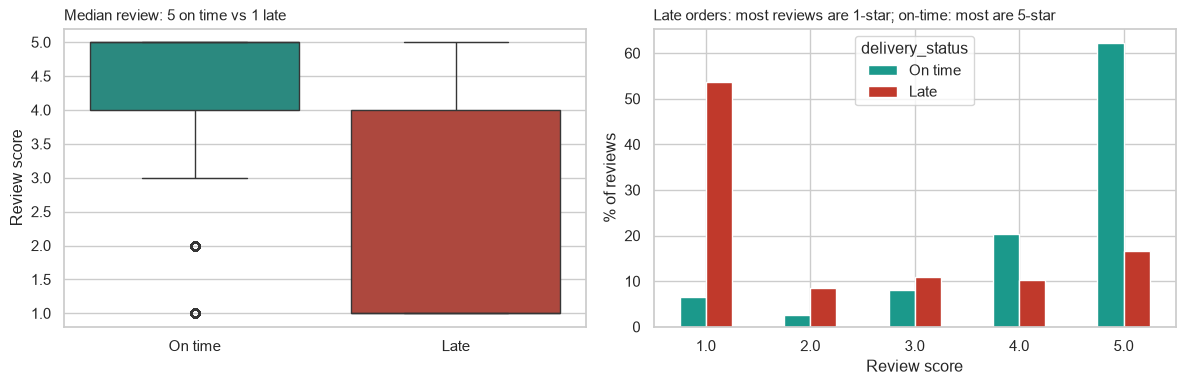

In [14]:
r = a.reviewed_measurable()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=r, x="delivery_status", y="review_score", order=["On time", "Late"],
            palette=[ON_TIME, LATE], ax=axes[0])
axes[0].set_title(f"Median review: {res['median_on_time']:.0f} on time vs {res['median_late']:.0f} late",
                  loc="left", fontsize=11)
axes[0].set_xlabel(""); axes[0].set_ylabel("Review score")
dist = pd.crosstab(r["delivery_status"], r["review_score"], normalize="index").loc[["On time", "Late"]] * 100
dist.T.plot(kind="bar", color=[ON_TIME, LATE], ax=axes[1])
axes[1].set_title("Late orders: most reviews are 1-star; on-time: most are 5-star", loc="left", fontsize=11)
axes[1].set_ylabel("% of reviews"); axes[1].set_xlabel("Review score"); axes[1].tick_params(axis="x", rotation=0)
fig.tight_layout(); save(fig, "07_review_late_vs_on_time.png"); plt.show()

**Result:** the average review is **2.271** for late orders vs **4.29** for on-time orders.
The Mann-Whitney p-value is below 0.001 (and the Welch t-test agrees, t = -100.74), so we **reject H0**.

**In business words:** if late delivery made no difference to reviews, a gap this large would almost never happen by chance.
Late delivery is strongly associated with worse reviews. The effect is large, not just significant (rank-biserial
effect size 0.638): it is not a statistical technicality caused by the big sample.

**Test 2: Chi-square test of independence (late vs negative review)**
* **H0:** whether an order is late and whether its review is negative (1-2 stars) are independent.
* **H1:** they are associated. alpha = 0.05.
* **Why this test:** both variables are categorical (yes/no), and every expected cell count is far above 5.

In [15]:
chi = a.chi_square("is_late", "is_negative")
display(chi["table"].rename(index={0: "On time", 1: "Late"}, columns={0: "Not negative", 1: "Negative"}))
print({k: v for k, v in chi.items() if k != "table"})

is_negative,Not negative,Negative
is_late,,
On time,81153,8290
Late,2399,3982


{'chi2': 15054.6, 'p_value': 0.0, 'dof': 1, 'cramers_v': 0.396, 'reject_H0': True, 'min_expected': 817.2}


**Result:** chi-square = 15,054.6, p < 0.001: **reject H0**. Late delivery and
negative reviews are not independent; Cramér's V = 0.396 shows a moderate-to-strong
association. Note this shows association, not proof that lateness alone causes the bad review (some late orders also
had damaged or wrong items).

## 6. Q9: What is the probability of a negative review given a late delivery vs an on-time one?

P(negative | late)    = 0.624
P(negative | on time) = 0.093
Relative risk         = 6.73x


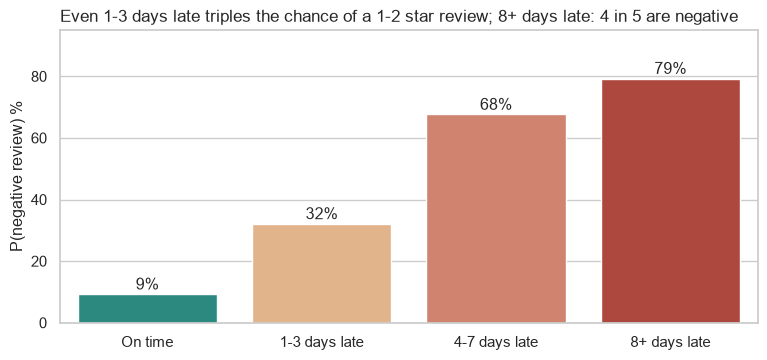

,reviewed_orders,p_negative
delay_bucket,,
On time,89443,0.0927
1-3 days late,1852,0.3213
4-7 days late,1748,0.6762
8+ days late,2781,0.7929


In [16]:
p = a.negative_review_probability()
print(f"P(negative | late)    = {p['p_negative_given_late']:.3f}")
print(f"P(negative | on time) = {p['p_negative_given_on_time']:.3f}")
print(f"Relative risk         = {p['relative_risk']}x")
bucket = p["by_bucket"]
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.barplot(x=bucket.index, y=bucket["p_negative"] * 100, palette=[ON_TIME, "#F0B37E", "#E07A5F", LATE], ax=ax)
for i, v in enumerate(bucket["p_negative"] * 100):
    ax.text(i, v + 1.5, f"{v:.0f}%", ha="center")
ax.set_ylim(0, 95); ax.set_ylabel("P(negative review) %"); ax.set_xlabel("")
ax.set_title("Even 1-3 days late triples the chance of a 1-2 star review; 8+ days late: 4 in 5 are negative",
             loc="left", fontsize=12)
save(fig, "08_negative_review_by_delay_bucket.png"); plt.show()
bucket

**Finding (Q9):** P(negative | late) = **62.4%** vs P(negative | on time) =
**9.3%**: a late order is **6.73x** as likely to get a 1-2 star review.
The risk climbs with every bucket: 32% at 1-3 days late, 68% at 4-7 days and
79% at 8+ days. This answers the Head of CX: there is no "safe" amount of lateness.

## 7. Q10: Which factors explain delivery time?

Candidate drivers: product weight, freight value, inter-state shipping (seller and customer in different states),
and seller handover days. First a correlation matrix, then ordinary least-squares regression (NumPy).

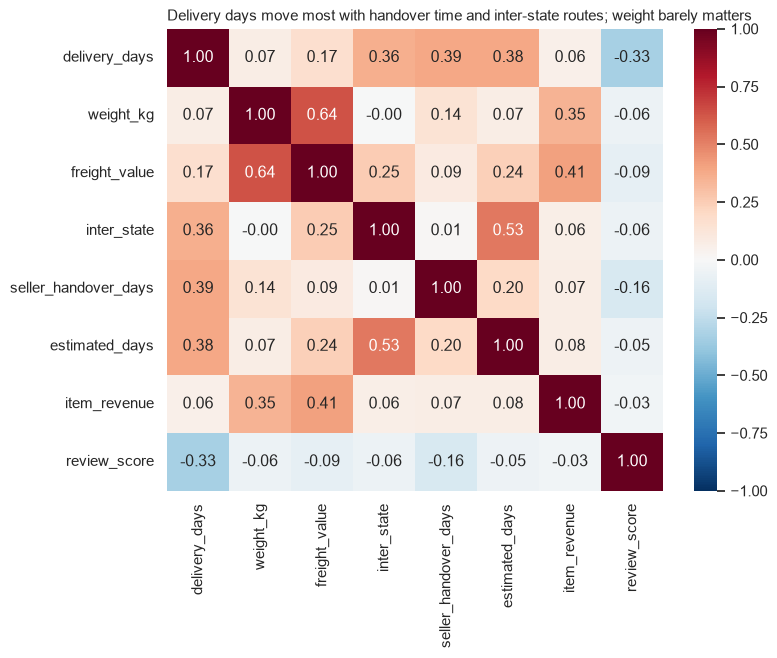

In [17]:
corr_cols = ["delivery_days", "weight_kg", "freight_value", "inter_state", "seller_handover_days",
             "estimated_days", "item_revenue", "review_score"]
corr = m[corr_cols].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Delivery days move most with handover time and inter-state routes; weight barely matters",
             loc="left", fontsize=11)
save(fig, "09_correlation_heatmap.png"); plt.show()

In [18]:
reg1 = a.regression(x=("weight_kg", "freight_value", "inter_state"))
print(f"Model 1 (brief's factors): n = {reg1['n']:,}, R² = {reg1['r_squared']}")
display(reg1["coefficients"])
reg2 = a.regression(x=("weight_kg", "freight_value", "inter_state", "seller_handover_days"))
print(f"Model 2 (+ seller handover days): R² = {reg2['r_squared']}")
display(reg2["coefficients"])

Model 1 (brief's factors): n = 96,470, R² = 0.1379


,coefficient,std_error,t,p_value
intercept,7.3934,0.0521,141.9821,0.0
weight_kg,0.0745,0.0080,9.3287,0.0
freight_value,0.0242,0.0018,13.2160,0.0
inter_state,6.9291,0.0631,109.8639,0.0


Model 2 (+ seller handover days): R² = 0.2808


,coefficient,std_error,t,p_value
intercept,4.7521,0.0518,91.6820,0.0
weight_kg,-0.0433,0.0074,-5.8523,0.0
freight_value,0.0269,0.0017,15.9644,0.0
inter_state,6.8156,0.0582,117.1772,0.0
seller_handover_days,1.0481,0.0076,137.3309,0.0


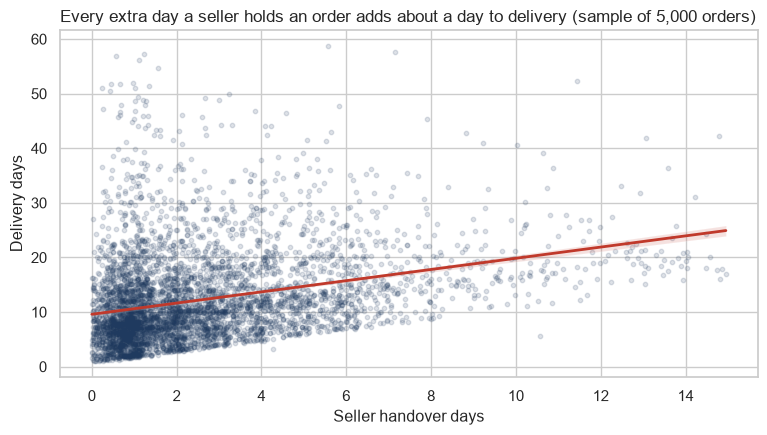

In [19]:
sample = m[["seller_handover_days", "delivery_days"]].dropna()
sample = sample[(sample["seller_handover_days"] <= 15) & (sample["delivery_days"] <= 60)].sample(5000, random_state=42)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.regplot(data=sample, x="seller_handover_days", y="delivery_days", scatter_kws={"alpha": 0.15, "s": 10, "color": NAVY},
            line_kws={"color": LATE, "lw": 2}, ax=ax)
ax.set_title("Every extra day a seller holds an order adds about a day to delivery (sample of 5,000 orders)",
             loc="left", fontsize=12)
ax.set_xlabel("Seller handover days"); ax.set_ylabel("Delivery days")
save(fig, "10_handover_vs_delivery_scatter.png"); plt.show()

**Interpretation:**
* **Model 1** (weight, freight, inter-state) explains **14%** of the variation in delivery days (R² = 0.1379).
  Holding the others constant, an **inter-state** order takes **6.9 days longer** than a
  same-state order. Each extra kg adds only 0.07 days and each extra R$ 1 of freight
  0.024 days: statistically significant (huge sample) but practically small.
* **Model 2** adds seller handover days and R² doubles to **28%**. Each extra handover day adds
  **1.05 delivery days**, almost one-for-one.

**Limits (state these when presenting):**
* R² of 0.28 means most variation is unexplained: distance, carrier, region and season are missing.
* This is association, not causation: heavier items are also more often inter-state, so effects overlap
  (weight even changes sign once handover is added).
* Delivery days are right-skewed, so residuals are not normal; coefficients are fine for direction and size, but
  p-values should be read with care.

## 8. Q11: Do customers whose first order was late return less often?

* **H0:** whether a customer's first order was late is independent of whether they ever order again.
* **H1:** they are associated. Chi-square test, alpha = 0.05.

Repeat customer rate overall: 3.12% of 96,096 customers (counted by customer_unique_id; by customer_id it would look like 0%)


,customers,repeat_rate
first_order,,
Late,6344,0.0254
On time,86905,0.0313


{'chi2': 6.7, 'p_value': 0.009903816167452348, 'dof': 1, 'cramers_v': 0.008, 'reject_H0': True, 'min_expected': 195.8}


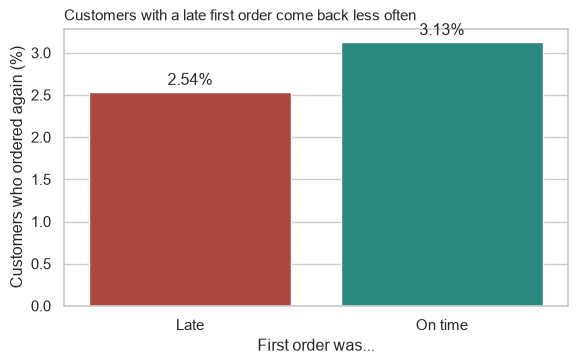

In [20]:
first, ret = a.retention_by_first_order()
print(f"Repeat customer rate overall: {kpis['repeat_customer_pct']}% of {kpis['customers']:,} customers "
      f"(counted by customer_unique_id; by customer_id it would look like 0%)")
display(ret)
chi_r = a.chi_square("first_order", "returned", first)
print({k: v for k, v in chi_r.items() if k != "table"})
fig, ax = plt.subplots(figsize=(6.5, 3.6))
sns.barplot(x=ret.index, y=ret["repeat_rate"] * 100, palette=[LATE, ON_TIME], ax=ax)
for i, v in enumerate(ret["repeat_rate"] * 100):
    ax.text(i, v + 0.08, f"{v:.2f}%", ha="center")
ax.set_ylabel("Customers who ordered again (%)"); ax.set_xlabel("First order was...")
ax.set_title("Customers with a late first order come back less often", loc="left", fontsize=11)
save(fig, "11_retention_first_order.png"); plt.show()

**Finding (Q11):** only **3.12%** of 96,096 customers ever order twice. Customers whose
first order was late return at **2.54%** vs **3.13%**
when it was on time: about 19% fewer returners.
The chi-square p-value is 0.010 (< 0.05), so the difference is statistically significant, but the
effect is small (Cramér's V = 0.008). Late delivery hurts retention, but low repeat purchase is a
wider problem than delivery alone.

## 9. Change request CR-01 (Finance): instalments, AOV and cancellations

**Request (Day 4):** "Do orders paid in more instalments have a higher AOV or more cancellations?"
Logged as CR-01 in the change log; impact: one extra analysis section, one Excel chart (already in the quick-look) and
one SQL query (SQL-04b). No change to KPI definitions. Sponsor approval recorded in the Confluence decision log.

,orders,aov_brl,cancellation_pct
instalment_band,,,
1 (single),48270,99.94,1.35
2-3,22792,114.05,1.07
4-6,16205,157.04,1.13
7+,12173,301.27,1.27


Spearman correlation, instalments vs order value: {'spearman_rho': 0.375, 'p_value': 0.0}


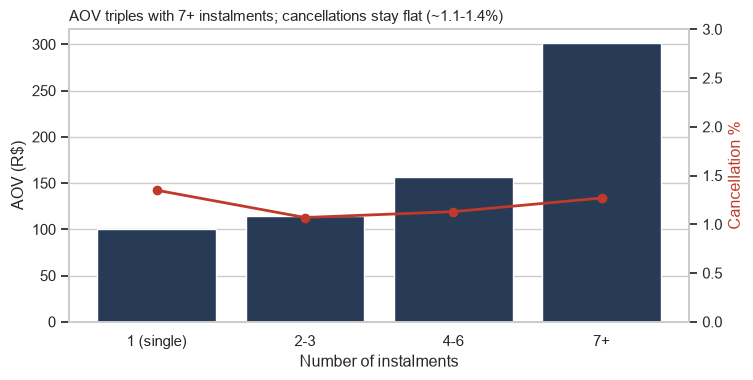

In [21]:
inst, rho = a.instalment_analysis()
display(inst); print("Spearman correlation, instalments vs order value:", rho)
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.barplot(x=inst.index.astype(str), y=inst["aov_brl"], color=NAVY, ax=ax)
ax2 = ax.twinx(); ax2.plot(range(len(inst)), inst["cancellation_pct"], color=LATE, marker="o", lw=2)
ax2.set_ylim(0, 3); ax2.set_ylabel("Cancellation %", color=LATE); ax2.grid(False)
ax.set_ylabel("AOV (R$)"); ax.set_xlabel("Number of instalments")
ax.set_title("AOV triples with 7+ instalments; cancellations stay flat (~1.1-1.4%)", loc="left", fontsize=11)
save(fig, "12_instalments_aov_cancellation.png"); plt.show()

**Finding (CR-01):** AOV rises from **R$ 100** (single payment) to
**R$ 301** (7+ instalments); Spearman rho = 0.375 (p < 0.001). Cancellation rates
stay between 1.07% and 1.35% with no upward trend. Instalments
enable bigger baskets without more cancellations. Caveat: causation probably runs the other way (expensive items are
paid in instalments), so this supports keeping interest-free instalments, not forcing them.

## 10. Key findings

1. **Late delivery is strongly associated with bad reviews.** Late orders average 2.271 stars vs 4.29
   (Mann-Whitney p < 0.001, large effect). A late order is 6.73x as likely to get a 1-2 star review.
2. **There is no safe lateness.** P(negative) rises from 9% on time to 32% at 1-3 days,
   68% at 4-7 days and 79% at 8+ days late.
3. **On-time % is high overall (93.23%) but collapses at volume peaks:** 2018-03 fell to
   81.0%, and monthly review scores track on-time % closely.
4. **Estimated dates are heavily padded:** promised 23.7 days vs actual 12.6;
   74% arrive 8+ days early. There is room to promise faster dates without hurting on-time %.
5. **Inter-state shipping is the biggest structural delay:** +6.9 days vs same-state orders
   (same-state average 7.9 days vs inter-state 15.1).
6. **Seller handover is the controllable lever:** each extra handover day adds ~1.0
   delivery day. A what-if cap of 3 handover days would lift on-time from 93.23% to 94.6%
   (+1.3 points).
7. **The carrier leg is the largest stage** (9.33 of 12.56 days), longest for remote
   North/Northeast states.
8. **Retention is very low (3.12%)** and lower still after a late first order
   (2.54% vs 3.13%, significant but small effect).
9. **Black Friday (2017-11) is the single biggest event**: plan carrier and seller capacity ahead of it.
10. **CR-01:** more instalments mean higher AOV (R$ 301 at 7+) with no rise in cancellations.

**Limits:** observational data (association, not causation); 2016 and Sep-Oct 2018 excluded from trends; regression
explains 28% of delivery time; review text not analysed.

## 11. Recommendation sizing (what-if scenarios)

Each recommendation in the memo is sized here, so every number traces to this cell. Method: change one driver, keep
everything else the same, recount late orders. Negative reviews avoided = late orders fixed ×
(P(negative | late) − P(negative | on time)). These are estimates from observational data, not guarantees, and the
scenarios overlap, so they are not additive.

In [22]:
# --- sizing ---
d = a.measurable().copy()
p = a.negative_review_probability()
gap = p["p_negative_given_late"] - p["p_negative_given_on_time"]
base_late = d["is_late"].sum()
rows = []

# R1: peak months held at the 95% target
d["month"] = d["order_purchase_timestamp"].dt.to_period("M").astype(str)
peak = d[d["month"].isin(["2017-11", "2017-12", "2018-02", "2018-03"])]
fixed = int(peak["is_late"].sum() - len(peak) * 0.05)
rows.append(("R1 Peak months at 95% on time", fixed, 1 - (base_late - fixed) / len(d)))

# R2: seller handover capped at 3 days
h = d["seller_handover_days"].fillna(0)
new_delay = np.ceil(d["delay_days"] - np.maximum(0, h - 3))
fixed = int(((d["is_late"] == 1) & (new_delay <= 0)).sum())
rows.append(("R2 Handover capped at 3 days", fixed, (new_delay <= 0).mean()))

# R3: watch-list sellers brought to the average late rate of all other sellers
items = loader.load("order_items.csv")
sc = pd.read_csv(os.path.join("..", "06_dashboards", "data", "vw_seller_scorecard.csv"))
watch = set(sc.loc[sc["watch_status"] == "Watch list", "seller_id"])
w_orders = set(items.loc[items["seller_id"].isin(watch), "order_id"])
dw = d[d["order_id"].isin(w_orders)]
rest_rate = d.loc[~d["order_id"].isin(w_orders), "is_late"].mean()
fixed = int(dw["is_late"].sum() - len(dw) * rest_rate)
rows.append((f"R3 {len(watch)} watch-list sellers at average late rate", fixed, 1 - (base_late - fixed) / len(d)))

sizing = pd.DataFrame(rows, columns=["scenario", "late_orders_fixed", "new_on_time"])
sizing["on_time_lift_pts"] = (sizing["new_on_time"] - (1 - base_late / len(d))) * 100
sizing["negative_reviews_avoided"] = (sizing["late_orders_fixed"] * gap).round()
sizing["new_on_time"] = (sizing["new_on_time"] * 100).round(2)
display(sizing.round(2))
print(f"Peak months: {len(peak):,} orders, on-time {100 * (1 - peak['is_late'].mean()):.1f}%")
print(f"Watch-list orders: {len(dw):,} ({100 * len(dw) / len(d):.1f}% of volume), late {100 * dw['is_late'].mean():.1f}% vs {100 * rest_rate:.1f}% for the rest")

# R4 check: a blanket cut of the estimate by N days (why we recommend a pilot, not a blanket cut)
cut = pd.DataFrame({"days_cut": [3, 5, 7],
                    "on_time_%": [round(100 * ((d["delay_days"] + n) <= 0).mean(), 1) for n in (3, 5, 7)]})
display(cut)
for ss, label in [(1, "Same state"), (0, "Inter-state")]:
    x = d[d["same_state"] == ss]
    print(f"{label}: promised {x['estimated_days'].mean():.1f} days, actual {x['delivery_days'].mean():.1f}, "
          f"on-time {100 * (1 - x['is_late'].mean()):.1f}%, on-time if cut by 3 days {100 * ((x['delay_days'] + 3) <= 0).mean():.1f}%")


,scenario,late_orders_fixed,new_on_time,on_time_lift_pts,negative_reviews_avoided
0,R1 Peak months at 95% on time,2251,95.56,2.33,1196.0
1,R2 Handover capped at 3 days,1278,94.55,1.32,679.0
2,R3 110 watch-list sellers at average late rate,663,93.91,0.69,352.0


Peak months: 26,359 orders, on-time 86.5%
Watch-list orders: 10,790 (11.2% of volume), late 12.2% vs 6.1% for the rest


,days_cut,on_time_%
0,3,88.8
1,5,85.0
2,7,78.9


Same state: promised 17.6 days, actual 7.9, on-time 95.5%, on-time if cut by 3 days 89.8%
Inter-state: promised 27.2 days, actual 15.1, on-time 92.0%, on-time if cut by 3 days 88.2%


In [23]:
extra = {
    "q8_mann_whitney": a.test_review_late_vs_on_time(),
    "q8_chi_square_late_vs_negative": {k: v for k, v in a.chi_square("is_late", "is_negative").items() if k != "table"},
    "q9_conditional_probability": {k: v for k, v in a.negative_review_probability().items() if k != "by_bucket"},
    "q10_regression_r_squared": {"model_1": reg1["r_squared"], "model_2_with_handover": reg2["r_squared"]},
    "q10_regression_coefficients_model_2": reg2["coefficients"]["coefficient"].round(3).to_dict(),
    "q11_repeat_rate_by_first_order": ret["repeat_rate"].to_dict(),
    "cr01_instalments": inst.reset_index().astype({"instalment_band": str}).to_dict(orient="records"),
}
path = a.export_kpis("kpi_summary.json", extra)
print("Saved", os.path.abspath(path))

Saved C:\Users\AWAN.Admin\Desktop\E-commerce capstone project\Script\05_python\kpi_summary.json
